# Lab 2 - Model Engineering
Compare BoW, FFNN, RNN and GNN for malware classification from API call sequences.

In [12]:
import pandas as pd
import numpy as np


train_data = pd.read_json("train.json")
test_data = pd.read_json("test.json")

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

#train_data.head()
#test_data.head()

print("Label:", train_data.loc[0, "is_malware"])
print("First 10 API calls:", train_data.loc[0, "api_call_sequence"][:10])


Training samples: 16325
Test samples: 6505


,api_call_sequence,is_malware
0,"[LdrGetDllHandle, LdrGetProcedureAddress, LdrL...",1
1,"[NtAllocateVirtualMemory, LdrLoadDll, LdrGetPr...",1
2,"[FindResourceExW, LoadResource, FindResourceEx...",1
3,"[FindResourceExW, LoadResource, FindResourceEx...",1
4,"[LdrGetProcedureAddress, SetErrorMode, LdrLoad...",1


## Post Processing - checks
Check missing values, valid sequences, labels and duplicates before preprocessing.

In [31]:
# Validate data before analysis and splitting
for name, data in [("Train", train_data), ("Test", test_data)]:
    print(f"\n{name}")
    print("Missing values:")
    print(data[["api_call_sequence", "is_malware"]].isna().sum())

    invalid_sequences = 0
    sequence_labels = {}
    duplicate_sequences = 0

    for sequence, label in zip(data["api_call_sequence"], data["is_malware"]):
        valid = isinstance(sequence, list) and len(sequence) > 0
        if valid:
            for call in sequence:
                if not isinstance(call, str) or not call.strip():
                    valid = False
                    break

        if not valid:
            invalid_sequences += 1
            continue

        key = tuple(sequence)
        if key in sequence_labels:
            duplicate_sequences += 1
        else:
            sequence_labels[key] = set()
        sequence_labels[key].add(label)

    conflicting_sequences = 0
    for labels in sequence_labels.values():
        if len(labels) > 1:
            conflicting_sequences += 1

    invalid_labels = (~data["is_malware"].isin([0, 1])).sum()
    print("Invalid sequences:", invalid_sequences)
    print("Invalid labels:", invalid_labels)
    print("Duplicate sequences (extra rows):", duplicate_sequences)
    print("Sequences with conflicting labels:", conflicting_sequences)
    assert invalid_sequences == 0 and invalid_labels == 0, "Inspect invalid rows"



Train
Missing values:
api_call_sequence    0
is_malware           0
dtype: int64
Invalid sequences: 0
Invalid labels: 0
Duplicate sequences (extra rows): 0
Sequences with conflicting labels: 0

Test
Missing values:
api_call_sequence    0
is_malware           0
dtype: int64
Invalid sequences: 0
Invalid labels: 0
Duplicate sequences (extra rows): 0
Sequences with conflicting labels: 0


# Analytics

Evaluating class distributions and other info

Training class counts:
is_malware
1    15714
0      611
Name: count, dtype: int64

Training class percentages:
is_malware
1    96.257274
0     3.742726
Name: proportion, dtype: float64

Test class counts:
is_malware
1    6262
0     243
Name: count, dtype: int64

Test class percentages:
is_malware
1    96.264412
0     3.735588
Name: proportion, dtype: float64
              Train         Test
count  16325.000000  6505.000000
mean      75.030812    86.331130
std        8.951411     9.113511
min       60.000000    70.000000
25%       67.000000    79.000000
50%       75.000000    87.000000
75%       83.000000    94.000000
max       90.000000   100.000000


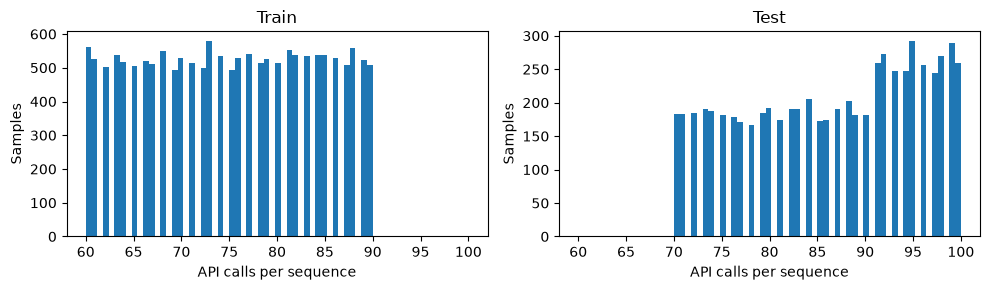

In [20]:
# Some info regarding the different class 
print("Training class counts:")
print(train_data["is_malware"].value_counts())

print("\nTraining class percentages:")# in percentuali 
print(train_data["is_malware"].value_counts(normalize=True).mul(100))

print("\nTest class counts:")
print(test_data["is_malware"].value_counts())

print("\nTest class percentages:")
print(test_data["is_malware"].value_counts(normalize=True).mul(100))

#max lenght of api_call_sequence

train_data["sequence_length"] = train_data["api_call_sequence"].apply(len)
test_data["sequence_length"] = test_data["api_call_sequence"].apply(len)

length_summary = pd.DataFrame({
    "Train": train_data["sequence_length"].describe(),
    "Test": test_data["sequence_length"].describe()
})

print(length_summary)


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)

for ax, (name, df) in zip(
    axes, [("Train", train_data), ("Test", test_data)]
):
    ax.hist(df["sequence_length"], bins=50)
    ax.set_title(name)
    ax.set_xlabel("API calls per sequence")
    ax.set_ylabel("Samples")

plt.tight_layout()
plt.show()






## Train split & validation

In [23]:
from sklearn.model_selection import train_test_split # type: ignore

train_split, val_split = train_test_split(
    train_data,
    test_size=0.2,
    stratify=train_data["is_malware"],
    random_state=42
)

print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))

Training samples: 13060
Validation samples: 3265


In [26]:
# Vocabulary size

train_vocab = set()

for sequence in train_split["api_call_sequence"]:
    for call in sequence:
        train_vocab.add(call)

print("Vocabulary size:", len(train_vocab))

# Test one
test_vocab = set()

for sequence in test_data["api_call_sequence"]:
    for call in sequence:
        test_vocab.add(call)

unseen_calls = test_vocab - train_vocab

print("Distinct unseen test calls:", len(unseen_calls))
print("Unseen calls:", sorted(unseen_calls))

# Calcolo unseen calls per sample in the test set
samples_with_unseen = 0

for sequence in test_data["api_call_sequence"]:
    for call in sequence:
        if call not in train_vocab:
            samples_with_unseen += 1
            break

print("Test samples with unseen calls:", samples_with_unseen)

Vocabulary size: 256
Distinct unseen test calls: 3
Unseen calls: ['ControlService', 'NtDeleteKey', 'WSASocketA']
Test samples with unseen calls: 3


## Task 2A - Unigram Bag-of-Words
Represent each sequence using API call counts, ignoring call order, and train a baseline classifier.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer # type: ignore

vectorizer = CountVectorizer(
    analyzer="word",
    tokenizer=list,
    token_pattern=None,
    lowercase=False, # Original value
    ngram_range=(1, 1)#solo singole chiamate
)

#obv la fit solo su train_split, poi trasformo sia train che val
X_train = vectorizer.fit_transform(train_split["api_call_sequence"])
X_val = vectorizer.transform(val_split["api_call_sequence"])

y_train = train_split["is_malware"]
y_val = val_split["is_malware"]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)

first_sample = pd.Series(
    X_train[0].toarray().ravel(),
    index=vectorizer.get_feature_names_out()
)

first_sample[first_sample > 0]

Training matrix: (13060, 256)
Validation matrix: (3265, 256)


CreateActCtxW                         1
GetNativeSystemInfo                   1
GetSystemDirectoryW                   2
GetSystemWindowsDirectoryW            4
GetVolumeNameForVolumeMountPointW     1
LdrGetProcedureAddress               11
LdrLoadDll                            5
LoadStringW                           1
NtClose                               5
NtCreateFile                          1
NtCreateMutant                        1
NtCreateSection                       1
NtDuplicateObject                     1
NtMapViewOfSection                    1
NtOpenKey                             2
NtQueryValueKey                       2
RegCloseKey                          14
RegEnumKeyW                           1
RegOpenKeyExA                         2
RegOpenKeyExW                        14
RegQueryValueExW                     10
dtype: int64